# Analysis of the pre-game feature table

Walks through `data/processed/features/games_features.parquet`: is it sound, what is in it, and what is worth using?

| section | question |
|---|---|
| A. Integrity | Do the identities and ranges hold, and what do unplayed games really contain? |
| B. Coverage | Which features exist in which seasons, and at which forecast horizons? |
| C. Signal | Which features track the score, and which know something the closing line does not? |
| D. Redundancy | How many different things do the columns measure, and which window is best? |
| E. Drift | Whose level moves across seasons? |
| F. Value | What does each feature group add out of sample? |

Run in the `nfl` environment; a full run takes about a minute, most of it in C and F.

This notebook reads the table and writes nothing. The table is built by `scripts/build_features.py`, and `scripts/analyze_features.py` runs the same analysis and saves the report, figures and CSVs. The calculations live in `src/pmrisk/features/analysis.py`, which has tests.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pmrisk").exists())
sys.path.insert(0, str(ROOT / "src"))

from pmrisk.features.analysis import (DICTIONARY, ENCODING_FOR, GROUPS, coverage_by_season, describe_features, drift_table,
                                      features_for, forecast_coverage, group_value, integrity_checks, load_table, matchup_view,
                                      played, redundancy, signal_table, target_frame, window_matrix)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40, "display.max_rows", 80, "display.max_colwidth", None, "display.width", 200)

C = {"a": "#4C72B0", "b": "#DD8452", "ref": "#555555", "grid": "#E5E5E5"}
TEST_SEASONS = list(range(2010, 2026))
TITLES = {"margin": "Margin", "margin_vs_spread": "Margin net of the closing spread",
          "total_pts": "Total", "total_vs_line": "Total net of the closing total"}


def heatmap(ax, m, vmax=None, fmt="{:.0%}", fontsize=7):
    im = ax.imshow(m.values, aspect="auto", cmap="Blues", vmin=0, vmax=vmax if vmax is not None else np.nanmax(m.values))
    ax.set_xticks(range(m.shape[1]), m.columns); ax.set_yticks(range(m.shape[0]), m.index)
    ax.spines[:].set_visible(False); ax.tick_params(length=0)
    limit = im.norm.vmin + 0.6 * (im.norm.vmax - im.norm.vmin)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize, color="white" if v > limit else "#222222")

## Load

One row per game, home-team orientation. Unplayed 2026 games have features and null targets.

`matchup_view` reduces each home/away pair to `diff_x = home_x - away_x`, which goes with the margin, and `avg_x = (home_x + away_x) / 2`, which goes with the total. It leaves out targets, market columns and numeric IDs. Everything below except the integrity checks runs on this view.

In [2]:
g = load_table()
dictionary = pd.read_csv(DICTIONARY)
p = played(g)
X = matchup_view(g)
Xp, targets = X.loc[p.index], target_frame(p)
info = describe_features(X.columns)

print(f"{len(g):,} games x {g.shape[1]} columns, {g.season.min()}-{g.season.max()}: {len(p):,} played, {len(g) - len(p)} unplayed")
print(f"matchup view: {X.shape[1]} features")
display(pd.DataFrame({"table columns": dictionary.group.value_counts(), "view features": info.group.value_counts()}).fillna(0).astype(int))

7,548 games x 802 columns, 1999-2026: 7,384 played, 164 unplayed
matchup view: 527 features


,table columns,view features
group,,
identifiers,20,0
injuries,44,44
market,10,0
quarterback,23,18
ratings,68,48
situational,28,17
targets,5,0
team form,604,400


## A. Integrity

`fail` means the table is wrong. `warn` means it is usable, but whoever models on it needs to know.

In [3]:
checks = integrity_checks(g, dictionary)
print(checks.status.value_counts().to_dict())
display(checks[checks.status != "pass"][["status", "check", "n_bad", "detail"]].sort_values("status").reset_index(drop=True))
print("Passed:", "; ".join(checks.check[checks.status == "pass"]))

{'pass': 17, 'warn': 8, 'fail': 1}


,status,check,n_bad,detail
0,fail,a starter with prior dropbacks keeps that history,111,"career_dropbacks = 0 on 56 unplayed and 55 played team-games, e.g. 2026_09_TB_CHI, 2026_09_BUF_MIN, 2026_09_BUF_MIN; the merge in qb_features needs a row for this game"
1,warn,home_win is 0.5 on a tie,16,coded [0.0]; winner contracts pay 0.5
2,warn,overround not negative,1,2020_01_LV_CAR
3,warn,"weather plausible (wind <= 40 mph, temp in -30..120 F)",3,"2008_02_TEN_CIN, 2016_13_NYG_PIT, 2023_13_SF_PHI"
4,warn,external ids are not numeric,3,"gsis, pff, ftn pass an is_numeric_dtype feature filter"
5,warn,rolling windows stay populated on unplayed games,2,l4 null on 70% of unplayed games; l8 null on 41% of unplayed games
6,warn,QB experience is null when no starter is named,136,"0 reads as a debut; e.g. 2026_10_WAS_NYG, 2026_10_NE_DET, 2026_10_JAX_TEN"
7,warn,injury counts are null when no report exists,152,"no report yet is stored as 0 injured on unplayed games; e.g. 2026_08_CHI_SEA, 2026_09_JAX_BAL, 2026_09_CIN_ATL"
8,warn,feature dictionary files ids under identifiers,8,"gsis, pff, ftn, old_game_id, nfl_detail_id"


Passed: game_id unique; game_id matches season, week and teams; at most one game per team and week; franchise codes follow relocations; targets all present or all absent; margin = home_score - away_score; total_pts = home_score + away_score; no unplayed game before the last played one; diff_x = home_x - away_x (228 pairs); elo_diff = home_elo + home field - away_elo; no infinite values; no constant columns; probabilities in [0, 1]; spread_line positive when the home team is favoured; no feature has |rho| > 0.6 with its own game's score; rolling form is null in a team's first game; feature dictionary lists exactly the table's columns


The QB failure, up close: a starter's history only attaches if they recorded dropbacks in that game, so a named starter on an unplayed game reads as a debut.

In [4]:
cols = ["game_id", "home_qb_id", "home_qb_name", "home_qb_career_dropbacks", "home_qb_ewm_epa_db"]
future = g.loc[g.home_score.isna() & g.home_qb_id.notna(), cols].head(6)

latest = p[p.home_qb_career_dropbacks > 0].sort_values("kickoff").groupby("home_qb_id").tail(1)
latest = latest[["home_qb_id", "game_id", "home_qb_career_dropbacks"]].rename(columns={"game_id": "latest_home_game", "home_qb_career_dropbacks": "dropbacks_then"})
display(future.merge(latest, on="home_qb_id", how="left").drop(columns="home_qb_id"))

,game_id,home_qb_name,home_qb_career_dropbacks,home_qb_ewm_epa_db,latest_home_game,dropbacks_then
0,2026_08_ATL_TB,Baker Mayfield,0.0,NaN,2026_03_MIN_TB,4481.0
1,2026_08_CLE_PIT,Aaron Rodgers,0.0,NaN,2026_05_IND_PIT,10377.0
2,2026_08_MIN_DET,Jared Goff,0.0,NaN,2026_07_GB_DET,6074.0
3,2026_08_LV_NYJ,Geno Smith,0.0,NaN,2026_07_MIA_NYJ,3616.0
4,2026_08_TEN_CIN,Joe Burrow,0.0,NaN,2026_04_JAX_CIN,3412.0
5,2026_08_BAL_BUF,Josh Allen,0.0,NaN,2026_04_NE_BUF,4991.0


## B. Coverage

Share of non-null values. Team form starts below 100% because CPOE, aDOT and pass rate over expected begin in 2006; injury counts begin in 2009 and snap-weighted injuries in 2013.

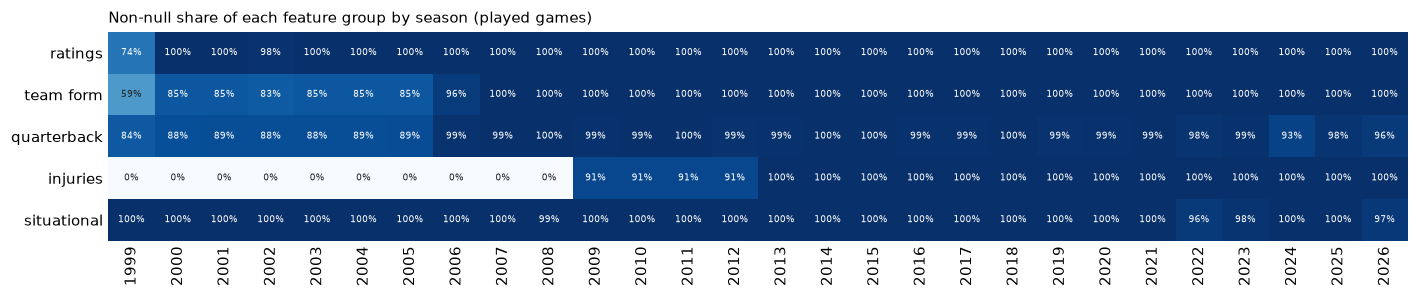

In [5]:
cov = coverage_by_season(Xp, p.season)
by_group = cov.groupby(info.group).mean().reindex(list(GROUPS))

fig, ax = plt.subplots(figsize=(13, 2.8))
heatmap(ax, by_group, vmax=1, fontsize=6)
ax.tick_params(axis="x", rotation=90)
ax.set_title("Non-null share of each feature group by season (played games)", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

What a forecast has to work with on unplayed games. Rolling windows run over the empty future rows, so `l4` and `l8` empty out with the horizon. `injury report` counts games with at least one non-zero count, because an absent report is stored as zeros.

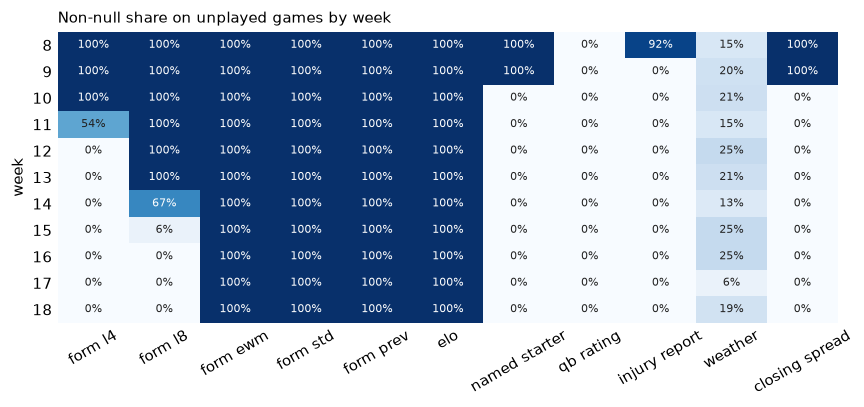

In [6]:
fc = forecast_coverage(g)

fig, ax = plt.subplots(figsize=(8, 3.8))
heatmap(ax, fc, vmax=1)
ax.tick_params(axis="x", rotation=30); ax.set(ylabel="week")
ax.set_title("Non-null share on unplayed games by week", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

## C. Signal

Spearman correlation computed within each season and then averaged, so league-wide drift cannot pass as signal. The t statistic uses the spread across seasons, and `q` is the Benjamini-Hochberg adjustment across the features tested.

Margin targets use `diff_*`, total targets use `avg_*`, and unsided features enter both. The net-of-line targets ask whether a feature knows something the close does not. There are no costs here, and a correlation is not a bet.

In [7]:
signals = {t: signal_table(Xp[features_for(X.columns, t)], targets[t], p.season) for t in ENCODING_FOR}

display(pd.DataFrame({TITLES[t]: {"tested": len(s), "q < 5%": int((s.q < 0.05).sum()), "strongest": s.index[0], "rho": round(s.rho_mean.iloc[0], 3)}
                      for t, s in signals.items()}).T)

,tested,q < 5%,strongest,rho
Margin,271,226,diff_ewm_adj_margin,0.371
Margin net of the closing spread,271,0,diff_l8_drives,-0.039
Total,271,191,avg_ewm_yards_play,0.208
Total net of the closing total,271,2,avg_std_points_against,-0.054


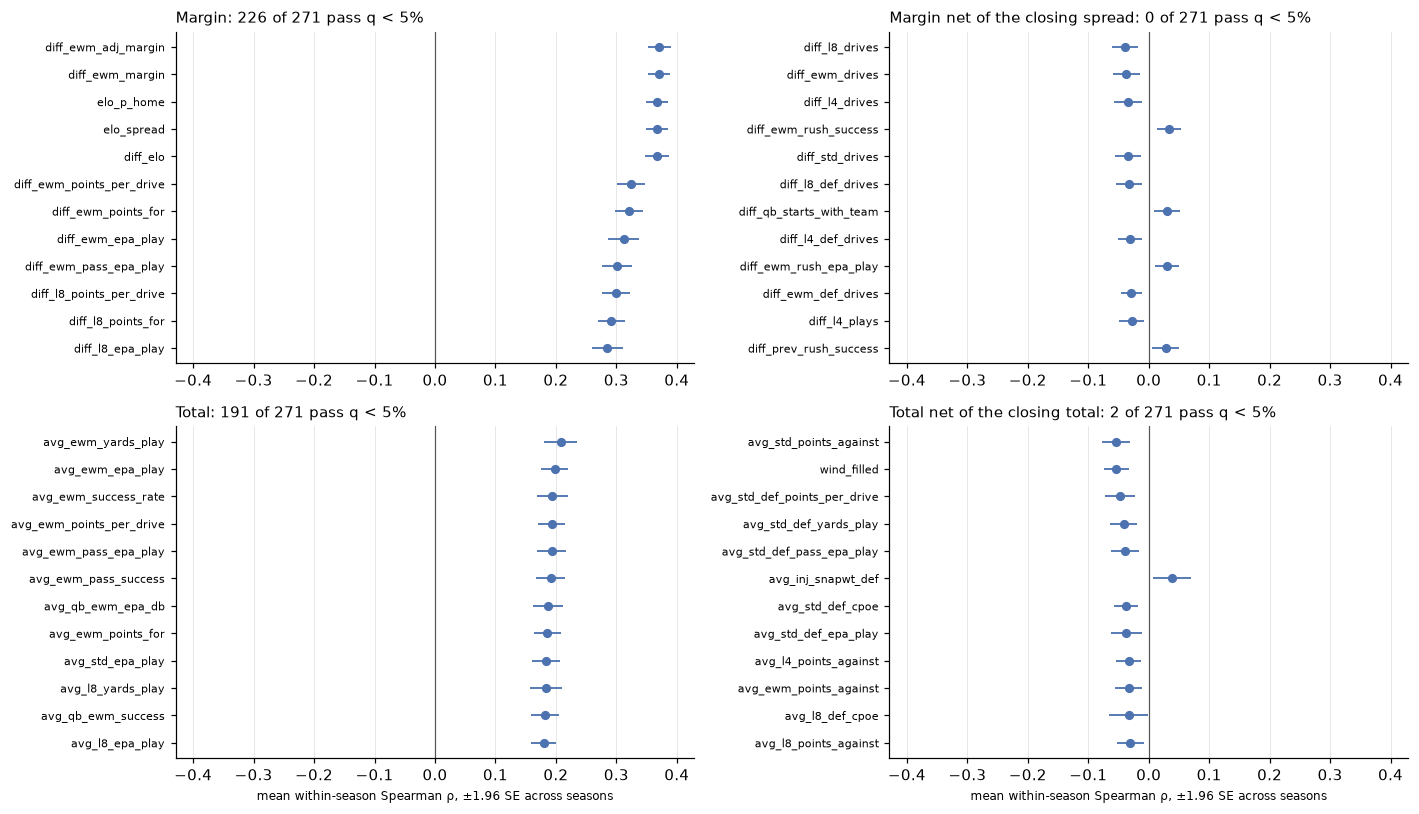

In [8]:
k = 12
lim = 1.1 * max((s.head(k).rho_mean.abs() + 1.96 * s.head(k).rho_se).max() for s in signals.values())
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, (target, s) in zip(axes.ravel(), signals.items()):
    top = s.head(k).iloc[::-1]
    ax.errorbar(top.rho_mean, range(len(top)), xerr=1.96 * top.rho_se, fmt="o", ms=5, color=C["a"], ecolor=C["a"], elinewidth=1.2)
    ax.axvline(0, color=C["ref"], lw=0.8)
    ax.set_yticks(range(len(top)), top.index, fontsize=7.5)
    ax.set_title(f"{TITLES[target]}: {int((s.q < 0.05).sum())} of {len(s)} pass q < 5%", loc="left", fontsize=10)
    ax.set_xlim(-lim, lim); ax.grid(axis="x", color=C["grid"], lw=0.6); ax.set_axisbelow(True); ax.tick_params(labelbottom=True)
for ax in axes[1]:
    ax.set_xlabel("mean within-season Spearman ρ, ±1.96 SE across seasons", fontsize=8)
fig.tight_layout(); plt.show()

The net-of-line tables, with early and late halves of the sample as a stability check. A feature here is a lead to test out of sample, not a result. `wind_filled` is observed game weather, so it is not a pre-game edge even if it survives.

In [9]:
cols = ["n_seasons", "rho_mean", "t", "q", "same_sign", "rho_early", "rho_late"]
for t in ("margin_vs_spread", "total_vs_line"):
    print(TITLES[t])
    display(signals[t].head(6)[cols].round(3))

Margin net of the closing spread


,n_seasons,rho_mean,t,q,same_sign,rho_early,rho_late
feature,,,,,,,
diff_l8_drives,28,-0.039,-3.509,0.178,0.786,-0.034,-0.044
diff_ewm_drives,28,-0.037,-3.299,0.178,0.750,-0.029,-0.045
diff_l4_drives,28,-0.034,-2.902,0.180,0.679,-0.032,-0.037
diff_ewm_rush_success,28,0.034,3.368,0.178,0.786,0.035,0.034
diff_std_drives,28,-0.034,-3.055,0.178,0.679,-0.024,-0.043
diff_l8_def_drives,28,-0.033,-3.014,0.178,0.714,-0.030,-0.036


Total net of the closing total


,n_seasons,rho_mean,t,q,same_sign,rho_early,rho_late
feature,,,,,,,
avg_std_points_against,28,-0.054,-4.707,0.009,0.857,-0.057,-0.051
wind_filled,28,-0.054,-5.054,0.007,0.750,-0.041,-0.066
avg_std_def_points_per_drive,28,-0.047,-3.673,0.074,0.786,-0.047,-0.047
avg_std_def_yards_play,28,-0.041,-3.655,0.074,0.750,-0.026,-0.056
avg_std_def_pass_epa_play,28,-0.039,-3.302,0.122,0.750,-0.028,-0.050
avg_inj_snapwt_def,14,0.039,2.355,0.497,0.643,0.006,0.071


## D. Redundancy

Clusters are average-linkage on `1 - |r|`, cut at `|r| = 0.8`, using 2013 onward, when every feature exists. Each cluster's representative is the member most correlated with the target, which gives a pruned feature list.

,diff,avg
features,271,271
clusters,169,166
components for 90%,77,74
components for 95%,104,102


Largest diff_* clusters, named by their representative:


,cluster_size,rho
feature,,
diff_ewm_points_per_drive,8,0.324
diff_prev_points_per_drive,7,0.230
diff_ewm_adj_margin,5,0.371
diff_std_points_per_drive,4,0.264
diff_ewm_success_rate,4,0.280
diff_l4_points_per_drive,4,0.260
diff_ewm_drives,4,-0.127
diff_ewm_pass_oe,4,0.102
diff_ewm_pass_rate,4,-0.115


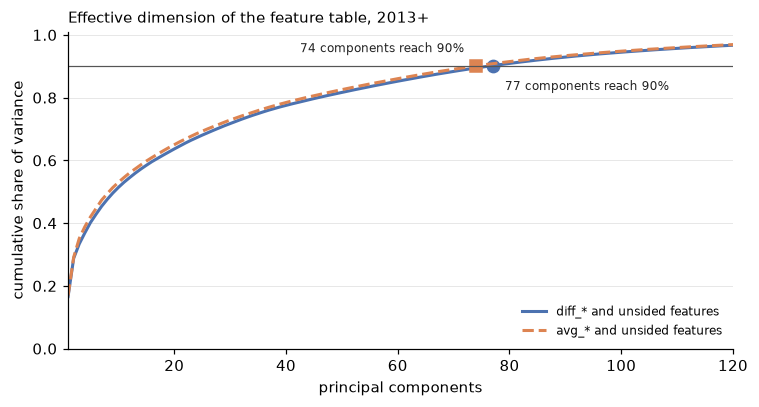

In [10]:
recent = p.season >= 2013
clusters, spectra = {}, {}
for enc, target in [("diff", "margin"), ("avg", "total_pts")]:
    clusters[enc], spectra[enc] = redundancy(Xp.loc[recent, features_for(X.columns, target)], signals[target].rho_mean)

display(pd.DataFrame({enc: {"features": len(clusters[enc]), "clusters": clusters[enc].cluster.nunique(),
                            "components for 90%": int(np.searchsorted(spectra[enc], 0.9) + 1),
                            "components for 95%": int(np.searchsorted(spectra[enc], 0.95) + 1)} for enc in clusters}))

print("Largest diff_* clusters, named by their representative:")
display(clusters["diff"][clusters["diff"].representative].sort_values("cluster_size", ascending=False).head(10)[["cluster_size", "rho"]].round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
styles = {"diff": (C["a"], "-", "o"), "avg": (C["b"], "--", "s")}
for enc, cum in spectra.items():
    color, ls, mk = styles[enc]
    n90 = int(np.searchsorted(cum, 0.9) + 1)
    ax.plot(np.arange(1, len(cum) + 1), cum, color=color, ls=ls, lw=2, label=f"{enc}_* and unsided features")
    ax.plot(n90, cum[n90 - 1], mk, color=color, ms=8)
    ax.annotate(f"{n90} components reach 90%", (n90, cum[n90 - 1]), xytext=(8, -16) if enc == "diff" else (-8, 9), textcoords="offset points",
                ha="left" if enc == "diff" else "right", fontsize=8, color="#222222")
ax.axhline(0.9, color=C["ref"], lw=0.8)
ax.set(xlim=(1, 120), ylim=(0, 1.01), xlabel="principal components", ylabel="cumulative share of variance")
ax.grid(axis="y", color=C["grid"], lw=0.6); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Effective dimension of the feature table, 2013+", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

Windows compared: `l4` and `l8` are the last 4 and 8 games, `ewm` an exponentially weighted mean across seasons, `std` season to date, and `prev` the previous season. Blank cells are statistics that exist in one window only.

,Margin,Total
strongest window,,
ewm,48,42
l4,0,2
l8,1,1
prev,2,3
std,0,3


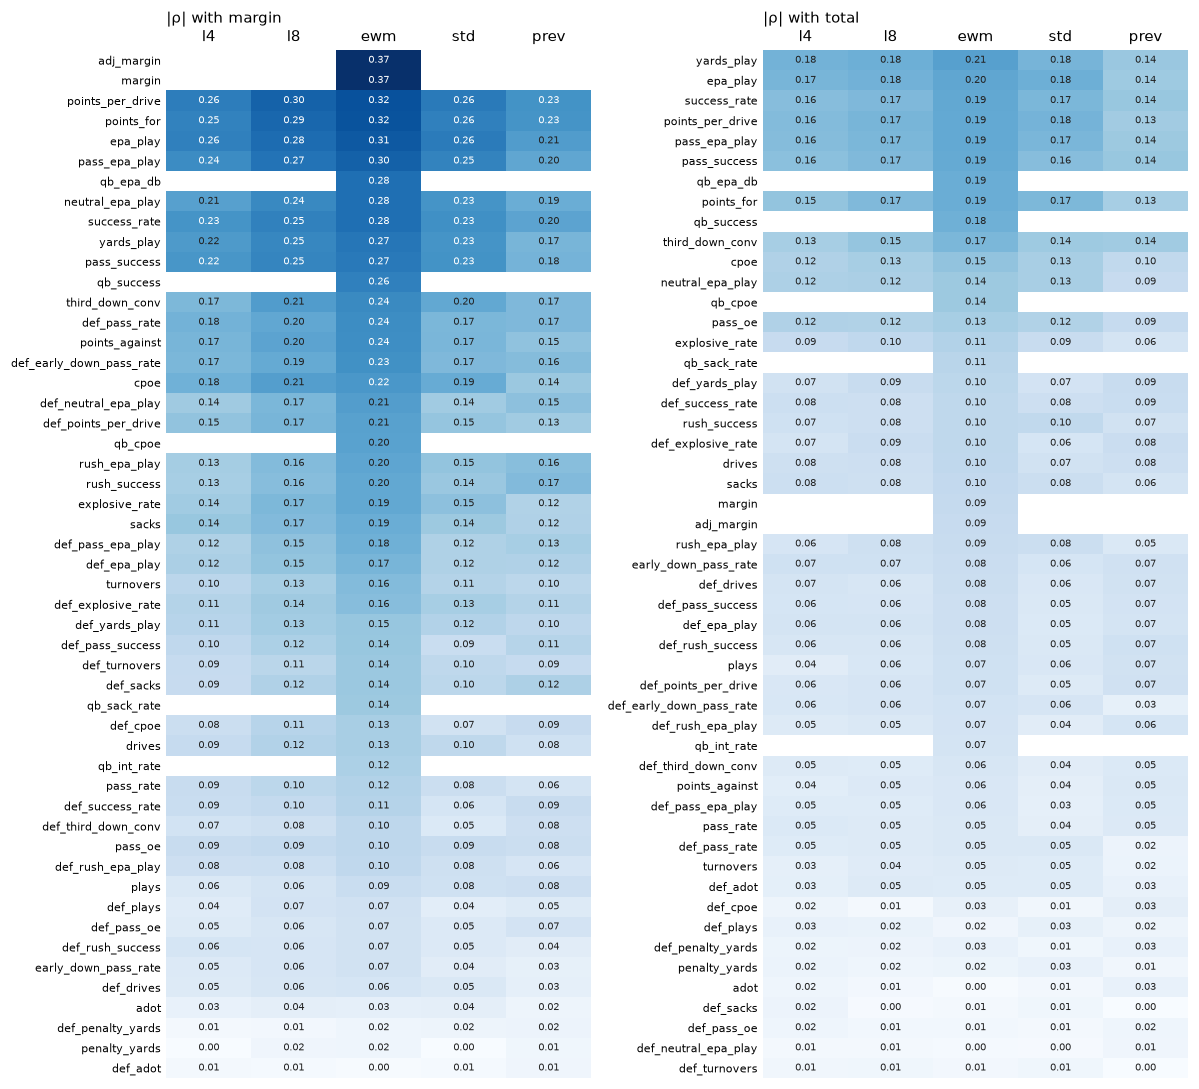

In [11]:
windows = {t: window_matrix(signals[t]) for t in ("margin", "total_pts")}
display(pd.DataFrame({TITLES[t]: m.idxmax(axis=1).value_counts() for t, m in windows.items()}).fillna(0).astype(int).rename_axis("strongest window"))

fig, axes = plt.subplots(1, 2, figsize=(11, 10))
vmax = max(np.nanmax(m.values) for m in windows.values())
for ax, (target, m) in zip(axes, windows.items()):
    heatmap(ax, m, vmax=vmax, fmt="{:.2f}", fontsize=6.5)
    ax.tick_params(axis="y", labelsize=7); ax.xaxis.tick_top()
    ax.set_title(f"|ρ| with {TITLES[target].lower()}", loc="left", fontsize=10, pad=18)
fig.tight_layout(); plt.show()

## E. Drift

For each feature, the share of variance between seasons (`eta2`) and the move from its first five seasons to its last five, in pooled standard deviations. Complete seasons only. `diff_*` is close to level-free by construction, so level shifts land in `avg_*` and matter most for models of the total.

,median,max
encoding,,
diff,0.01,0.07
avg,0.51,2.29


,eta2,first_mean,last_mean,shift_sd
feature,,,,
avg_ewm_def_drives,0.60,11.88,10.49,-2.29
avg_ewm_drives,0.59,11.88,10.49,-2.27
avg_prev_def_drives,0.56,11.82,10.52,-2.14
avg_prev_drives,0.55,11.82,10.52,-2.12
avg_l8_def_drives,0.48,11.85,10.47,-2.01
avg_l8_drives,0.47,11.85,10.47,-2.00
avg_std_drives,0.40,11.90,10.47,-1.85
avg_std_def_drives,0.40,11.87,10.47,-1.85


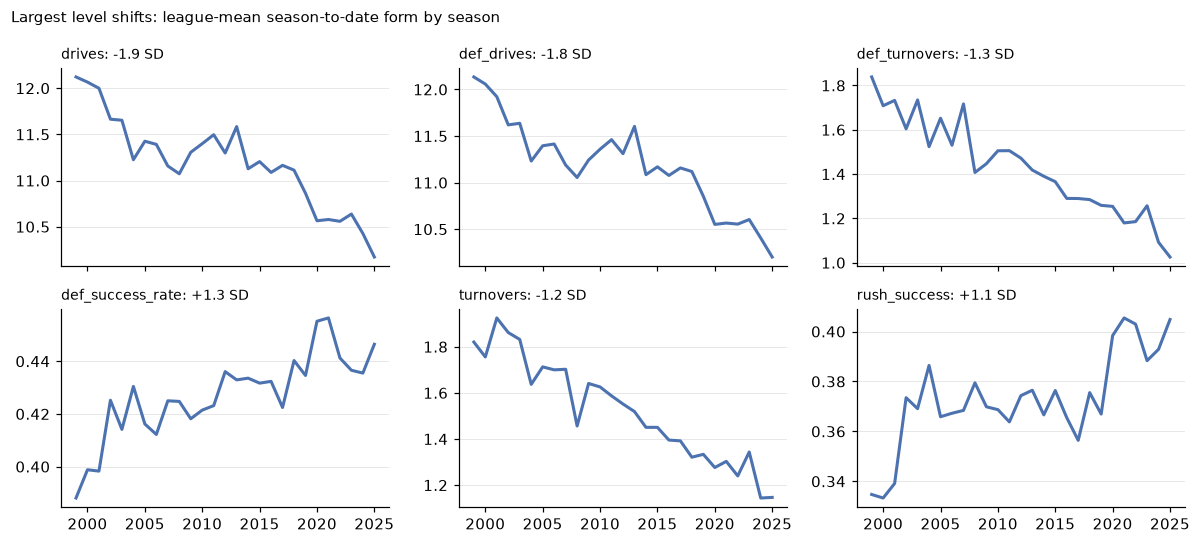

In [12]:
full = p.season <= 2025
drift, means = drift_table(Xp[full], p.season[full])

encoding = describe_features(drift.index).encoding
display(drift.shift_sd.abs().groupby(encoding.reindex(drift.index)).agg(["median", "max"]).round(2).loc[["diff", "avg"]])
display(drift.head(8).round(2))

d = describe_features(drift.index)
pick = drift[(d.encoding == "avg") & (d.window == "std")].head(6)  # one window per statistic, so six different things
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True)
for ax, name in zip(axes.ravel(), pick.index):
    s = means.loc[name].dropna()
    ax.plot(s.index, s.values, color=C["a"], lw=2)
    ax.set_title(f"{name[len('avg_std_'):]}: {pick.shift_sd[name]:+.1f} SD", loc="left", fontsize=9)
    ax.grid(axis="y", color=C["grid"], lw=0.6); ax.set_axisbelow(True)
fig.suptitle("Largest level shifts: league-mean season-to-date form by season", x=0.01, ha="left", fontsize=10)
fig.tight_layout(); plt.show()

## F. Value of each group

Ridge as in `scripts/baseline_models.py`, trained on seasons before `t` from 2000 on and tested on `t` in 2010-2025. `diff_vs_all` above 0 means the model errs by more than the all-groups ridge, so on an `all minus` row it is what that group adds. Standard errors are of the paired difference, clustered by week and by season.

QB features use the actual starter and weather is observed, so those groups assume information from close to kickoff.

In [13]:
value = pd.concat([group_value(Xp, p, "margin", "spread_line", TEST_SEASONS),
                   group_value(Xp, p, "total_pts", "total_line", TEST_SEASONS)], ignore_index=True)

for target, v in value.groupby("target", sort=False):
    print(f"{TITLES[target]} ({v.n.iloc[0]:,} games)")
    display(v[["model", "mae", "diff_vs_all", "se_week", "se_season", "t_week"]].set_index("model").round(3))

Margin (4,363 games)


,mae,diff_vs_all,se_week,se_season,t_week
model,,,,,
all groups,10.318,0.000,NaN,NaN,NaN
ratings only,10.335,0.017,0.034,0.028,0.502
all minus ratings,10.377,0.059,0.016,0.014,3.604
team form only,10.454,0.135,0.028,0.027,4.760
all minus team form,10.281,-0.037,0.023,0.022,-1.587
quarterback only,10.763,0.445,0.063,0.062,7.072
all minus quarterback,10.340,0.021,0.016,0.016,1.326
injuries only,11.134,0.815,0.077,0.061,10.598
all minus injuries,10.324,0.006,0.013,0.012,0.422


Total (4,363 games)


,mae,diff_vs_all,se_week,se_season,t_week
model,,,,,
all groups,10.608,0.000,NaN,NaN,NaN
ratings only,10.761,0.153,0.032,0.032,4.726
all minus ratings,10.610,0.002,0.007,0.006,0.317
team form only,10.693,0.085,0.018,0.018,4.660
all minus team form,10.630,0.022,0.025,0.026,0.848
quarterback only,10.759,0.151,0.044,0.063,3.466
all minus quarterback,10.653,0.045,0.009,0.011,4.854
injuries only,11.014,0.406,0.056,0.056,7.246
all minus injuries,10.594,-0.014,0.008,0.007,-1.864


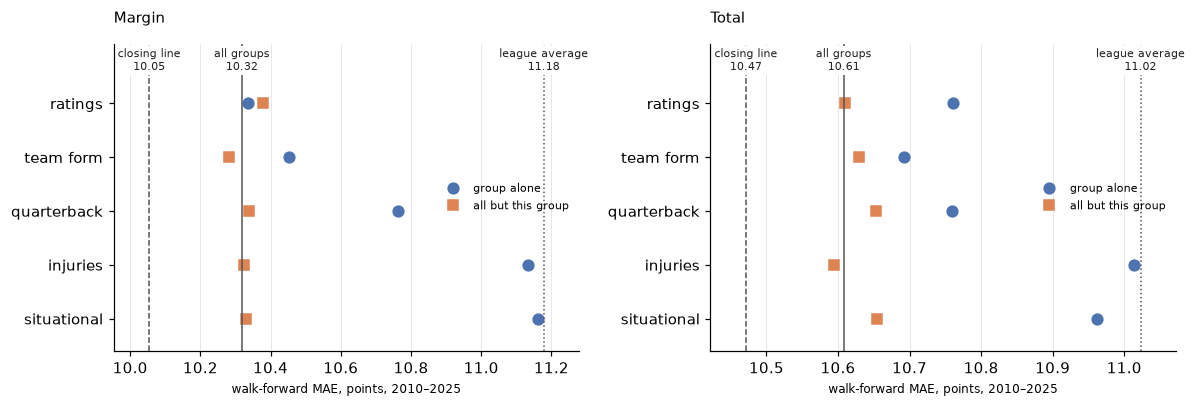

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (target, v) in zip(axes, value.groupby("target", sort=False)):
    v = v.set_index("model")
    y = np.arange(len(GROUPS))[::-1]
    ax.plot([v.mae[f"{grp} only"] for grp in GROUPS], y, "o", ms=7, color=C["a"], label="group alone", ls="")
    ax.plot([v.mae[f"all minus {grp}"] for grp in GROUPS], y, "s", ms=7, color=C["b"], label="all but this group", ls="")
    ax.set_yticks(y, GROUPS)
    top = len(GROUPS) - 0.45
    for name, ls in [("all groups", "-"), ("closing line", "--"), ("league average", ":")]:
        ax.axvline(v.mae[name], color=C["ref"], lw=1, ls=ls)
        ax.text(v.mae[name], top, f"{name}\n{v.mae[name]:.2f}", fontsize=7, ha="center", va="bottom", color="#222222", bbox=dict(fc="white", ec="none", pad=1))
    ax.margins(x=0.09); ax.set_ylim(-0.6, len(GROUPS) + 0.1); ax.set_xlabel("walk-forward MAE, points, 2010–2025", fontsize=8)
    ax.grid(axis="x", color=C["grid"], lw=0.6); ax.set_axisbelow(True)
    ax.set_title(TITLES[target], loc="left", fontsize=10, pad=14); ax.legend(frameon=False, fontsize=7.5, loc="center right")
fig.tight_layout(); plt.show()